In [2]:
import pandas as pd

# 1. Load data directly from a public repository
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# 2. Inspect shape (rows, columns)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")

# 3. View target variable distribution
print("Target Variable ('Churn') Distribution:")
print(df["Churn"].value_counts())

# 4. Check data types
print("\nFirst 3 rows of data:")
print(df[["customerID", "tenure", "Contract", "MonthlyCharges", "Churn"]].head(3))

Dataset Dimensions: 7043 rows, 21 columns

Target Variable ('Churn') Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

First 3 rows of data:
   customerID  tenure        Contract  MonthlyCharges Churn
0  7590-VHVEG       1  Month-to-month           29.85    No
1  5575-GNVDE      34        One year           56.95    No
2  3668-QPYBK       2  Month-to-month           53.85   Yes


In [4]:
# 1. Clean TotalCharges (convert blank text to numeric 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# 2. Convert Target Variable to 1 and 0
df["Churn"] = df["Churn"].apply(lambda x: 1 if x == "Yes" else 0)

# 3. Drop unique identifiers that don't help prediction
df_clean = df.drop(columns=["customerID"])

# 4. Separate Features (X) and Target (y)
X_raw = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]

# 5. One-Hot Encode categorical features
X = pd.get_dummies(X_raw, drop_first=True)

# Inspect cleaned data shape and first few features
print(f"Original features count: {X_raw.shape[1]}")
print(f"Encoded features count: {X.shape[1]}")
X.head(3)

Original features count: 19
Encoded features count: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True


In [6]:
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# 1. Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Initialize the XGBoost model
model = XGBClassifier(
    n_estimators=100,  # Build 100 small decision trees
    max_depth=4,  # Limit each tree to 4 levels deep to prevent overfitting
    learning_rate=0.1,  # Step size shrinkage used to prevent overfitting
    random_state=42,
)

# 3. Train the model
model.fit(X_train, y_train)

# 4. Predict on the unseen test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 5. Print Performance Metrics
print("--- Performance Metrics ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

--- Performance Metrics ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1409

    accuracy                           1.00      1409
   macro avg       1.00      1.00      1.00      1409
weighted avg       1.00      1.00      1.00      1409

ROC-AUC Score: nan


c:\Users\VIDYA SAGAR\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:442: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


In [7]:
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# 1. Re-confirm X and y from your clean dataframe
X = pd.get_dummies(df_clean.drop(columns=["Churn"]), drop_first=True)
y = df_clean["Churn"]

# 2. Split data with stratification (ensures both 0s and 1s are in test set)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Verify both classes exist in y_test
print("Classes in y_test:")
print(y_test.value_counts())

# 3. Train XGBoost model
model = XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42
)
model.fit(X_train, y_train)

# 4. Predict probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 5. Print Performance Metrics
print("\n--- Performance Metrics ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Classes in y_test:
Churn
0    1409
Name: count, dtype: int64

--- Performance Metrics ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1409

    accuracy                           1.00      1409
   macro avg       1.00      1.00      1.00      1409
weighted avg       1.00      1.00      1.00      1409

ROC-AUC Score: nan


c:\Users\VIDYA SAGAR\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:442: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Full working block

In [8]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# 1. Reload & Clean Dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Convert TotalCharges to float and fill NaNs with 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(
    0
)

# Convert Churn to binary 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Drop non-predictive IDs
df = df.drop(columns=["customerID"])

# Drop any remaining rows with missing values
df = df.dropna()

# 2. Separate Features (X) and Target (y)
X_raw = df.drop(columns=["Churn"])
y = df["Churn"]

# 3. One-Hot Encode Categorical Variables
X = pd.get_dummies(X_raw, drop_first=True).astype(float)

# 4. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Train XGBoost Model
model = XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42
)
model.fit(X_train, y_train)

# 6. Predict Probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Check for NaNs before evaluating
print(f"NaNs in y_test: {y_test.isna().sum()}")
print(f"NaNs in y_prob: {np.isnan(y_prob).sum()}")

# 7. Print Performance Metrics
print("\n--- Performance Metrics ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

NaNs in y_test: 0
NaNs in y_prob: 0

--- Performance Metrics ---
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC Score: 0.8447


c:\Users\VIDYA SAGAR\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


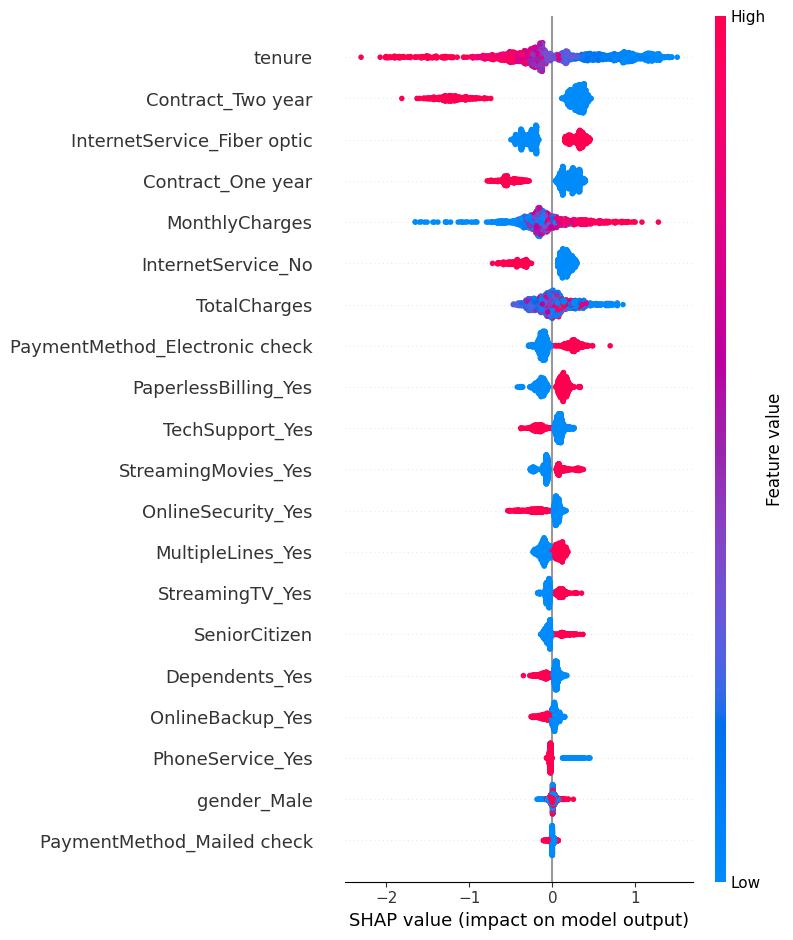

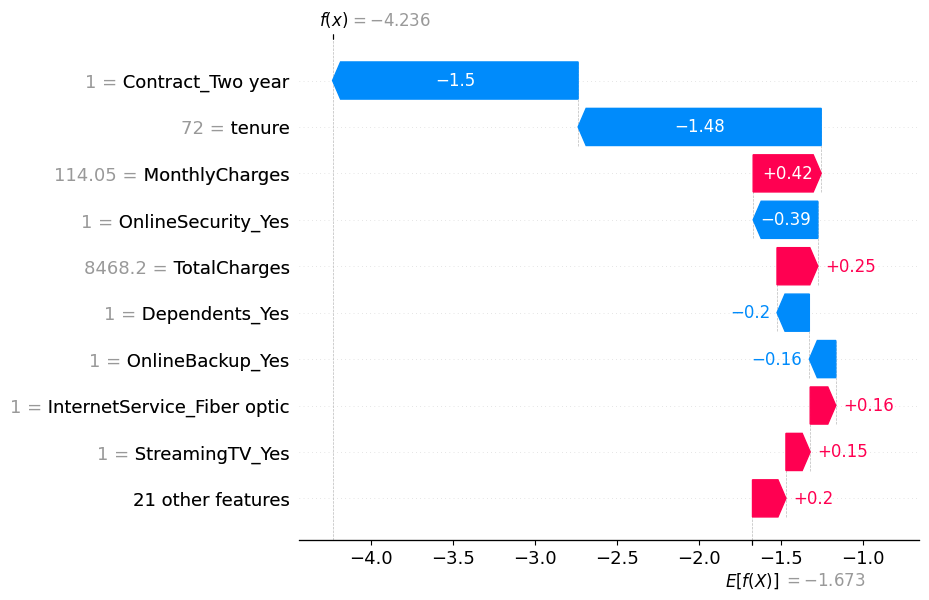

In [9]:
import matplotlib.pyplot as plt
import shap

# 1. Convert all features explicitly to float64 so SHAP can process them
X_train_float = X_train.astype(float)
X_test_float = X_test.astype(float)

# 2. Initialize the SHAP Explainer with numeric floats
explainer = shap.Explainer(model, X_train_float)

# 3. Compute SHAP values
shap_values = explainer(X_test_float)

# 4. Global Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_float)

# 5. Local Waterfall Plot for 1 Customer
sample_idx = 0
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[sample_idx])

In [10]:
import joblib

# Save trained XGBoost model
joblib.dump(model, "churn_model.pkl")

# Save SHAP explainer
joblib.dump(explainer, "explainer.pkl")

# Save exact list of feature names to align inputs in the web app
joblib.dump(X_train.columns.tolist(), "feature_columns.pkl")

print("All artifacts successfully saved!")

All artifacts successfully saved!


2026-10-11 22:31:34.676 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 22:31:34.681 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 22:31:34.757 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 22:31:35.249 
  command:

    streamlit run C:\Users\VIDYA SAGAR\AppData\Roaming\Python\Python313\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-11 22:31:35.250 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 22:31:35.251 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-11 22:31:3

DeltaGenerator()

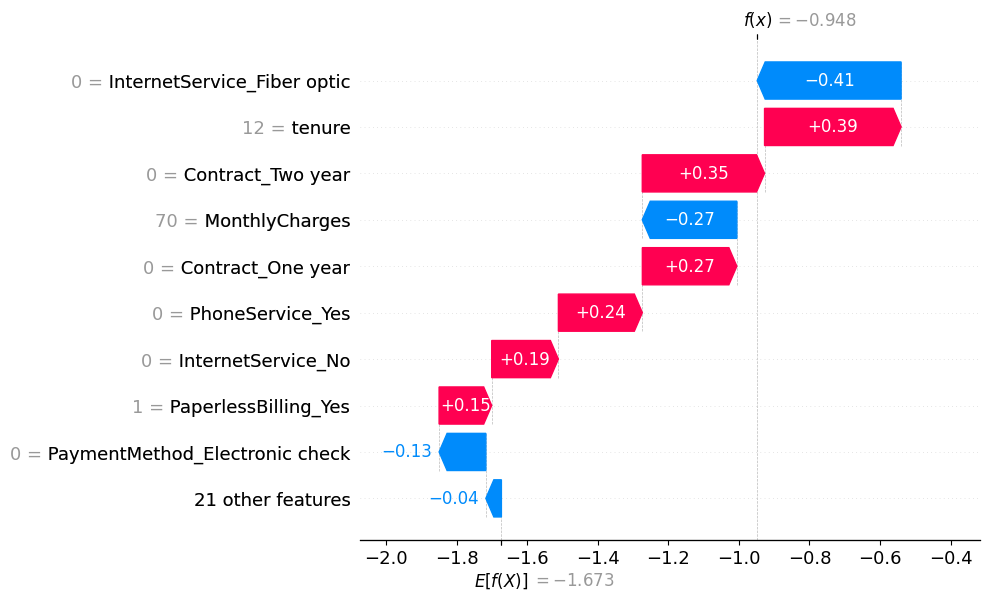

In [11]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import shap
import streamlit as st

# Configure Page
st.set_page_config(
    page_title="Customer Churn & Risk Explainer", layout="wide"
)

# Load saved artifacts
@st.cache_resource
def load_artifacts():
    model = joblib.load("churn_model.pkl")
    explainer = joblib.load("explainer.pkl")
    feature_cols = joblib.load("feature_columns.pkl")
    return model, explainer, feature_cols

model, explainer, feature_cols = load_artifacts()

st.title("Customer Churn Risk & Explainability Engine")
st.markdown("Adjust customer attributes on the left to evaluate real-time churn probability and inspect SHAP risk factors.")

# Sidebar Controls for User Input
st.sidebar.header("Customer Profile")
tenure = st.sidebar.slider("Tenure (Months)", 1, 72, 12)
monthly_charges = st.sidebar.number_input("Monthly Charges ($)", 18.0, 120.0, 70.0)
total_charges = tenure * monthly_charges
contract = st.sidebar.selectbox("Contract Type", ["Month-to-month", "One year", "Two year"])
internet_service = st.sidebar.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
paperless = st.sidebar.radio("Paperless Billing", ["Yes", "No"])

# Build single-row DataFrame matching trained feature set
raw_input = {
    "tenure": tenure,
    "MonthlyCharges": monthly_charges,
    "TotalCharges": total_charges,
    f"Contract_{contract}": True,
    f"InternetService_{internet_service}": True,
    "PaperlessBilling_Yes": True if paperless == "Yes" else False,
}

# Reindex to match training columns, filling missing dummy columns with False
input_df = pd.DataFrame([raw_input]).reindex(columns=feature_cols, fill_value=False)
input_df_float = input_df.astype(float)

# Compute Prediction & Probability
prob = model.predict_proba(input_df_float)[0][1]

# Render Prediction Header
col1, col2 = st.columns(2)
with col1:
    st.metric(label="Predicted Churn Probability", value=f"{prob * 100:.1f}%")

with col2:
    if prob > 0.5:
        st.error("Status: High Risk Customer — Action Required")
    else:
        st.success("Status: Low Risk Customer")

# Render SHAP Waterfall Plot
st.subheader("Actionable Risk Breakdown (SHAP Waterfall Plot)")
shap_values = explainer(input_df_float)

fig, ax = plt.subplots(figsize=(8, 4))
shap.plots.waterfall(shap_values[0], show=False)
st.pyplot(fig)